In [31]:
options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [32]:
library('tidymodels')

gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


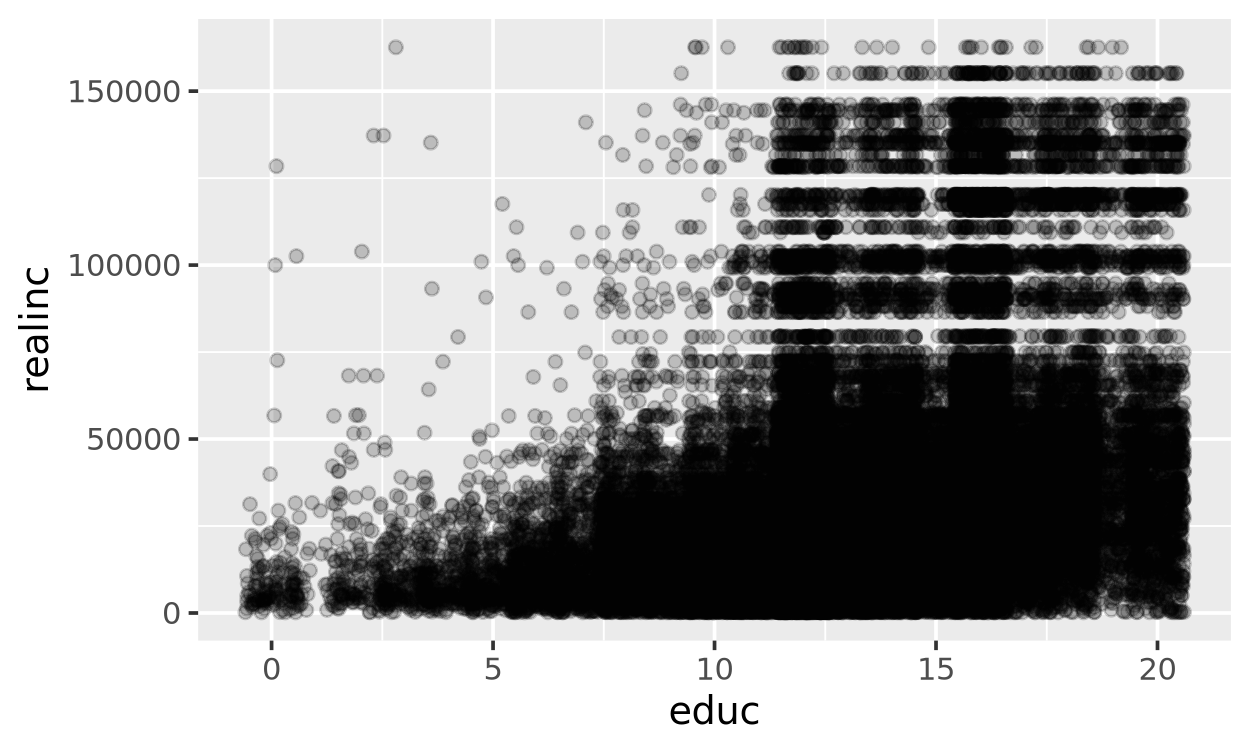

In [33]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(position = position_jitter(width = 0.6, height = 0.2), alpha = 0.2)

In [34]:
set.seed(512)

n_combos <- 250

params <- tibble(
    .rep = 1:n_combos,
    intercept = runif(n_combos, -50000, 50000),
    slope = runif(n_combos, 0, 5000)
)

params |> glimpse()

Rows: 250
Columns: 3
$ .rep      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> -11466.7282, -36613.3343, -4324.0748, 43243.4121, 14374.8909…
$ slope     <dbl> 1866.0072, 974.3479, 4735.2387, 2733.1077, 2388.0254, 3857.6…


In [35]:
income_by_educ <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE))

income_by_educ |> head()

  educ realinc 
1 0    11642.46
2 1    12030.38
3 2    18330.32
4 3    11435.07
5 4    11648.34
6 5    12475.96

In [36]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(
        aes(intercept = intercept, slope = slope),
        data = params, alpha = 0.05, color = 'steelblue'
    ) +
    geom_point()

ERROR: 

In [ ]:
intercept <- 0
slope <- 2500

income_by_educ |>
    mutate(pred = model1(c(intercept, slope), income_by_educ)) |>
    ggplot(aes(x = educ)) +
    geom_abline(intercept = intercept, slope = slope, color = 'grey40') +
    geom_segment(aes(y = realinc, yend = pred), color = 'red') +
    geom_point(aes(y = realinc))

In [ ]:
model1 <- function(a, data) {
    a[1] + a[2] * data$educ
}

Rmse_Fun <- function(intercept, slope, data = gss, model = model1) {
    pred <- model(c(intercept, slope), data)
    resid <- data$realinc - pred
    sqrt(mean(resid^2, na.rm = TRUE))
}

Rmse_Fun(intercept = 0, slope = 2500)

In [ ]:
params <- params |>
    rowwise() |>
    mutate(rmse = Rmse_Fun(intercept, slope)) |>
    ungroup()

params |> glimpse()

Steps for creating a model:

1. Pick the model form: $\text{realinc} = a_1 + a_2 \times \text{educ}$
2. Design a way to evaluate different model paramters.
3. Optimize our paramter value.

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


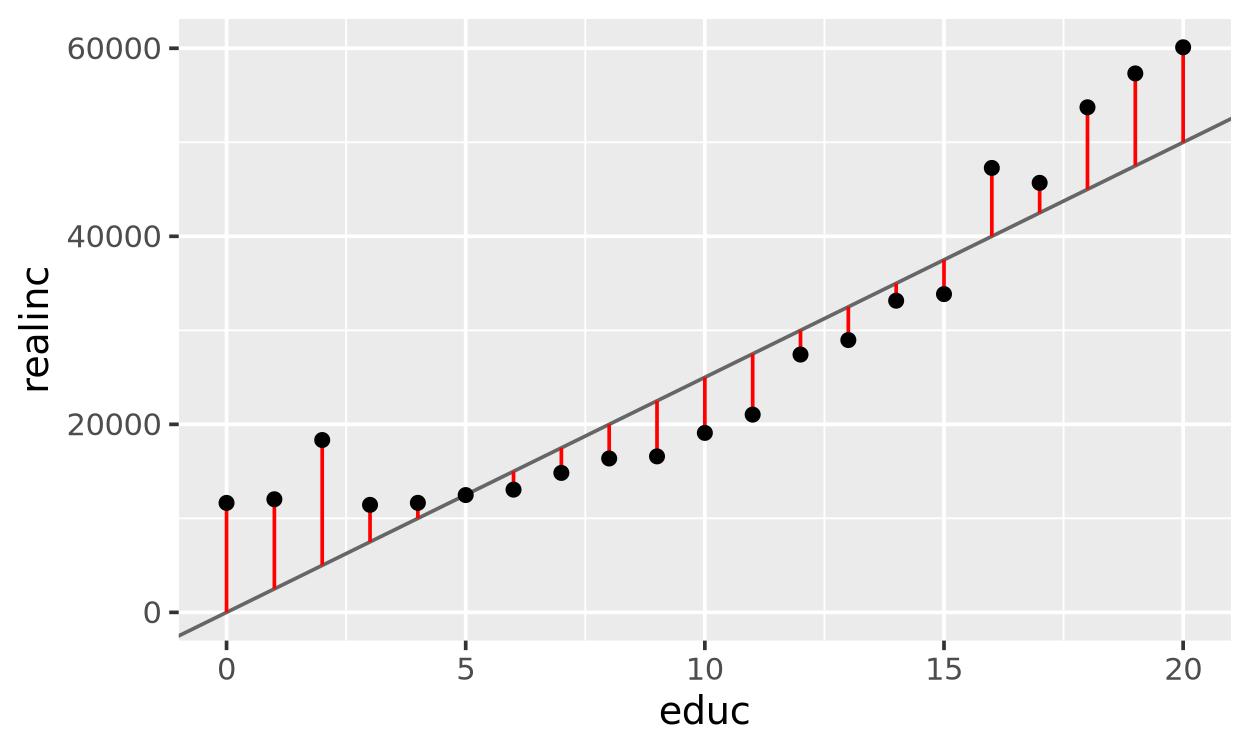

In [37]:
intercept <- 0
slope <- 2500
a <- c(intercept, slope)

pred  <- model1(a, gss)
resid <- gss$realinc - pred
sq    <- resid^2
mn    <- mean(sq, na.rm = TRUE)
rmse  <- sqrt(mn)

tibble(pred = pred, resid = resid, sq = sq) |> head()

tibble(mean_sq = mn, rmse = rmse)

income_by_educ |>
    mutate(pred = model1(a, income_by_educ)) |>
    ggplot(aes(x = educ)) +
    geom_abline(intercept = intercept, slope = slope, color = 'grey40') +
    geom_segment(aes(y = realinc, yend = pred), color = 'red') +
    geom_point(aes(y = realinc))

In [ ]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(
        aes(intercept = intercept, slope = slope, color = -rmse),
        data = params |> slice_min(rmse, n = 5)
    ) +
    geom_point()